In [1]:
import pandas as pd

df = pd.read_csv('../dataset/customer_support_tickets.csv')
df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [2]:
df.info()

missing_values = df.isnull().sum()
print("Missing Values:\n", missing_values)

duplicates = df.duplicated().sum()
print("\nTotal Duplicate Rows:", duplicates)

<class 'pandas.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   str    
 2   Customer Email                8469 non-null   str    
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   str    
 5   Product Purchased             8469 non-null   str    
 6   Date of Purchase              8469 non-null   str    
 7   Ticket Type                   8469 non-null   str    
 8   Ticket Subject                8469 non-null   str    
 9   Ticket Description            8469 non-null   str    
 10  Ticket Status                 8469 non-null   str    
 11  Resolution                    2769 non-null   str    
 12  Ticket Priority               8469 non-null   str    
 13  Ticket Channel

Ticket Categories:
 Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Ticket Priorities:
 Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64


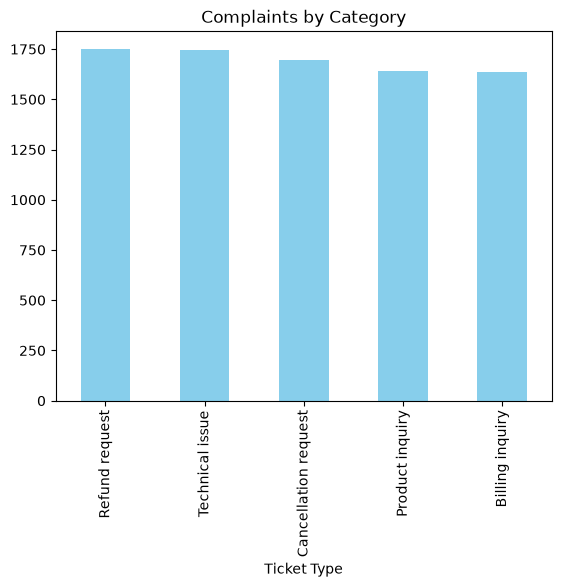

In [3]:
import matplotlib.pyplot as plt

category_counts = df['Ticket Type'].value_counts()
print("Ticket Categories:\n", category_counts)

priority_counts = df['Ticket Priority'].value_counts()
print("\nTicket Priorities:\n", priority_counts)

category_counts.plot(kind='bar', title='Complaints by Category', color='skyblue')
plt.show()

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nTicket Category Distribution:")
print(df['Ticket Type'].value_counts())

print("\nTicket Category Percentages:")
print(df['Ticket Type'].value_counts(normalize=True) * 100)

print("\nSample Ticket Subjects:")
print(df['Ticket Subject'].sample(10, random_state=42).tolist())

print("\nSample Ticket Descriptions:")
print(df['Ticket Description'].sample(10, random_state=42).tolist())

Dataset Shape: (8469, 17)

Column Names:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']

Ticket Category Distribution:
Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Ticket Category Percentages:
Ticket Type
Refund request          20.687212
Technical issue         20.628173
Cancellation request    20.014169
Product inquiry         19.376550
Billing inquiry         19.293895
Name: proportion, dtype: float64

Sample Ticket Subjects:
['Product setup', 'Battery life', 'Refund request', 'Peripheral compatibility', 'Peripheral compatibility', 'Refund request', 'Software bug', 'Install

In [5]:
description = df['Ticket Description']
subject = df['Ticket Subject']

print("Descriptions containing placeholders:",
      description.str.contains(r'\{[^}]+\}', regex=True, na=False).sum())

print("\nPercentage containing placeholders:",
      round(description.str.contains(r'\{[^}]+\}', regex=True, na=False).mean() * 100, 2), "%")

print("\nDuplicate descriptions:", description.duplicated().sum())

print("Duplicate subjects:", subject.duplicated().sum())

print("\nAverage description length:",
      description.str.len().mean())

print("\nShortest description:",
      description.str.len().min())

print("\nLongest description:",
      description.str.len().max())

print("\nMost common ticket subjects:")
print(subject.value_counts().head(15))

Descriptions containing placeholders: 8469

Percentage containing placeholders: 100.0 %

Duplicate descriptions: 392
Duplicate subjects: 8453

Average description length: 289.82193883575394

Shortest description: 151

Longest description: 397

Most common ticket subjects:
Ticket Subject
Refund request              576
Software bug                574
Product compatibility       567
Delivery problem            561
Hardware issue              547
Battery life                542
Network problem             539
Installation support        530
Product setup               529
Payment issue               526
Product recommendation      517
Account access              509
Peripheral compatibility    496
Data loss                   491
Cancellation request        487
Name: count, dtype: int64


In [6]:
import re

all_text = " ".join(df['Ticket Description'].dropna())

placeholders = re.findall(r'\{([^}]+)\}', all_text)

print("Unique Placeholders:")
print(pd.Series(placeholders).value_counts())

print("\nUnique Ticket Subjects:")
print(df['Ticket Subject'].nunique())

print("\nDuplicate descriptions with conflicting categories:")

duplicate_groups = df.groupby('Ticket Description')['Ticket Type'].nunique()

conflicting = duplicate_groups[duplicate_groups > 1]

print("Conflicting descriptions:", len(conflicting))

print("\nExamples of conflicting descriptions:")

if len(conflicting) > 0:
    print(
        df[df['Ticket Description'].isin(conflicting.index)]
        [['Ticket Description', 'Ticket Type']]
        .head(10).to_string(index=False)
    )

print("\nCategory distribution for each subject:")
print(pd.crosstab(df['Ticket Subject'], df['Ticket Type']))

Unique Placeholders:
product_purchased                                                                                                                                  13535
error_message                                                                                                                                        472
product_id                                                                                                                                            48
product_name                                                                                                                                          32
Product_purchased                                                                                                                                     18
                                                                                                                                                   ...  
 "name" : "Microsoft Kinect", "price" : "$40", "brand" : I've